# 03 · ResNet50: Transfer Learning for Skin Lesion Classification
**Project:** Deep Learning-Based Skin Cancer Detection and Classification Using Dermoscopic Image Analysis

This notebook is **fully self-contained**: it loads (or recreates) the lesion-grouped split from
notebook 01, trains an ImageNet-pre-trained **ResNet50** on the 7 HAM10000 classes, evaluates it on the
held-out test set with clinical metrics, explains predictions with **Grad-CAM**, and saves:

* the trained model → `models/resnet50.pth`
* the test metrics → `results/resnet50_metrics.json`
* all figures → `results/resnet50/`

## 0. Environment setup
This first cell detects whether the notebook runs on **Google Colab**. On Colab it installs the
required packages and uses `/content/skin-cancer-detection` as the project folder (select
*Runtime → Change runtime type → GPU*). Locally it uses the project root (the parent of `notebooks/`).
All paths are built with `pathlib`, so the notebook runs unchanged on macOS, Linux and Windows.

In [1]:
import sys, subprocess, os, json, time, random, warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle", "opencv-python-headless",
                    "seaborn", "scikit-learn", "pandas", "matplotlib"], check=True)
    ROOT = Path("/content/skin-cancer-detection")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"                # original HAM10000 download
PROCESSED_DIR = DATA_DIR / "processed"    # cached preprocessed 224x224 images
SPLITS_DIR = DATA_DIR / "splits"          # train/val/test CSVs
MODELS_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results"
for d in (RAW_DIR, PROCESSED_DIR, SPLITS_DIR, MODELS_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", category=UserWarning)
print("Running on Colab:", IN_COLAB)
print("Project root   :", ROOT)

Running on Colab: False
Project root   : /Users/udaymallikarjun/Documents/sanya/skincancer/skin-cancer-detection


## 1. Download HAM10000 (Kaggle API)
The dataset `kmader/skin-cancer-mnist-ham10000` is downloaded with the official `kaggle` package.
Both credential formats are supported: the **new API token** (`~/.kaggle/access_token` or the
`KAGGLE_API_TOKEN` environment variable) and the legacy `~/.kaggle/kaggle.json`. On Colab you are
asked to paste a token if none is configured. If the data is already present, the download is skipped.

In [2]:
import getpass

KAGGLE_DATASET = "kmader/skin-cancer-mnist-ham10000"

def dataset_present():
    has_csv = any(RAW_DIR.rglob("HAM10000_metadata.csv"))
    return has_csv and sum(1 for _ in RAW_DIR.rglob("ISIC_*.jpg")) >= 10000

def ensure_dataset():
    if dataset_present():
        print(f"HAM10000 already available in {RAW_DIR}")
        return
    kdir = Path.home() / ".kaggle"
    has_creds = (os.environ.get("KAGGLE_API_TOKEN") or (kdir / "access_token").exists()
                 or (kdir / "kaggle.json").exists())
    if not has_creds and IN_COLAB:
        kdir.mkdir(exist_ok=True)
        (kdir / "access_token").write_text(getpass.getpass("Paste your Kaggle API token: ").strip())
        os.chmod(kdir / "access_token", 0o600)
    from kaggle.api.kaggle_api_extended import KaggleApi
    api = KaggleApi()
    api.authenticate()
    print("Downloading HAM10000 (~2.7 GB) ...")
    api.dataset_download_files(KAGGLE_DATASET, path=str(RAW_DIR), unzip=True, quiet=False)
    print("Download complete:", dataset_present())

ensure_dataset()

HAM10000 already available in /Users/udaymallikarjun/Documents/sanya/skincancer/skin-cancer-detection/data/raw


## 2. Configuration
Class names, the benign/malignant mapping, preprocessing parameters and the compute device
(**CUDA → Apple MPS → CPU**).

In [3]:
import numpy as np
import pandas as pd
import torch

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_FULL_NAMES = {
    "akiec": "Actinic keratoses / intraepithelial carcinoma", "bcc": "Basal cell carcinoma",
    "bkl": "Benign keratosis-like lesions", "df": "Dermatofibroma", "mel": "Melanoma",
    "nv": "Melanocytic nevi", "vasc": "Vascular lesions"}
MALIGNANT_CLASSES = ["mel", "bcc", "akiec"]
BENIGN_CLASSES = ["nv", "bkl", "df", "vasc"]
BINARY_MAP = {c: ("Malignant" if c in MALIGNANT_CLASSES else "Benign") for c in CLASS_NAMES}
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
MALIGNANT_IDX = [CLASS_TO_IDX[c] for c in MALIGNANT_CLASSES]

IMG_SIZE = 224
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
HAIR_KERNEL_SIZE, HAIR_THRESHOLD, HAIR_MIN_LENGTH, INPAINT_RADIUS = 17, 12, 40, 3
CLAHE_CLIP_LIMIT, CLAHE_TILE_GRID = 2.0, (8, 8)
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15
SEED = 42

def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

DEVICE = get_device()
set_seed()
print("PyTorch", torch.__version__, "| device:", DEVICE)

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

MODEL_NAME = "resnet50"
EPOCHS = 15            # maximum number of epochs
MIN_EPOCHS = 10        # early stopping may only trigger after this many epochs
PATIENCE = 4           # stop after 4 epochs without validation macro-F1 improvement
BATCH_SIZE = 32
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0        # 0 = no multiprocessing (safe on Windows / macOS / notebooks)
OUT_DIR = RESULTS_DIR / MODEL_NAME
OUT_DIR.mkdir(parents=True, exist_ok=True)

PyTorch 2.14.1 | device: mps


## Preprocessing functions
The same preprocessing is used for training, evaluation and inference:

1. **Hair removal.** A morphological **black-hat** transform (closing minus image) highlights thin,
   dark structures such as hairs. After thresholding, only **long and thin** connected components are
   kept (so skin texture and the lesion's own pigment network are *not* erased), and the masked
   pixels are filled by **Telea inpainting**.
2. **CLAHE.** Contrast Limited Adaptive Histogram Equalisation on the *L* (lightness) channel of the
   LAB colour space enhances local contrast (borders, pigment network) without shifting lesion colours.
3. **Resize** to 224 × 224 pixels, the input size of the ImageNet backbones.
4. **Normalise** pixel values to [0, 1], then standardise with the ImageNet channel mean and std.

In [4]:
import cv2

def load_image_rgb(path):
    data = np.fromfile(str(path), dtype=np.uint8)          # works with non-ASCII Windows paths
    bgr = cv2.imdecode(data, cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError(f"Could not read {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def hair_mask(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (HAIR_KERNEL_SIZE, HAIR_KERNEL_SIZE))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, mask = cv2.threshold(blackhat, HAIR_THRESHOLD, 255, cv2.THRESH_BINARY)
    # keep only long, thin components (hairs); drops skin texture and the lesion's pigment network
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    w, h, area = stats[:, cv2.CC_STAT_WIDTH], stats[:, cv2.CC_STAT_HEIGHT], stats[:, cv2.CC_STAT_AREA]
    keep = (np.maximum(w, h) >= HAIR_MIN_LENGTH) & (area / np.maximum(w * h, 1) < 0.4)
    keep[0] = False
    mask = np.where(keep[labels], 255, 0).astype(np.uint8)
    return blackhat, cv2.dilate(mask, np.ones((3, 3), np.uint8), iterations=1)

def remove_hair(img_rgb):
    _, mask = hair_mask(img_rgb)
    return cv2.inpaint(img_rgb, mask, INPAINT_RADIUS, cv2.INPAINT_TELEA)

def apply_clahe(img_rgb):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=CLAHE_CLIP_LIMIT, tileGridSize=CLAHE_TILE_GRID)
    return cv2.cvtColor(cv2.merge((clahe.apply(l), a, b)), cv2.COLOR_LAB2RGB)

def preprocess_image(img_rgb, size=IMG_SIZE):
    """hair removal -> CLAHE -> resize. Returns RGB uint8 (size x size)."""
    h, w = img_rgb.shape[:2]
    scale = 600.0 / max(h, w)                                # fixed working resolution
    if abs(scale - 1.0) > 0.05:
        img_rgb = cv2.resize(img_rgb, (int(round(w * scale)), int(round(h * scale))), interpolation=cv2.INTER_AREA)
    img = apply_clahe(remove_hair(img_rgb))
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)

def normalize(img_rgb):
    img = img_rgb.astype(np.float32) / 255.0
    return (img - np.array(IMAGENET_MEAN, np.float32)) / np.array(IMAGENET_STD, np.float32)

def save_image_rgb(img_rgb, path):
    ok, buf = cv2.imencode(".jpg", cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 95])
    buf.tofile(str(path))

## 3. Load the train / validation / test split
HAM10000 contains several images of the same lesion. If those images ended up in both the training
and the test set, the model could memorise the lesion and the test score would be inflated. We
therefore split **unique `lesion_id`s** (70 / 15 / 15, stratified by diagnosis, seed 42), and every
image follows its lesion. Paths in the CSVs are stored relative to `data/raw/` so the files are
portable between machines and operating systems.

In [5]:
from sklearn.model_selection import train_test_split

def load_metadata():
    csv = sorted(RAW_DIR.rglob("HAM10000_metadata.csv"))[0]
    df = pd.read_csv(csv)
    paths = {}
    for p in RAW_DIR.rglob("ISIC_*.jpg"):
        paths.setdefault(p.stem, p)
    df["path"] = df["image_id"].map(paths)
    df = df.dropna(subset=["path"]).reset_index(drop=True)
    df["label"] = df["dx"].map(CLASS_TO_IDX)
    df["binary"] = df["dx"].map(BINARY_MAP)
    return df

def _resolve(df):
    df = df.copy()
    df["path"] = df["path"].map(lambda rel: str(RAW_DIR / Path(rel)))
    return df

def make_splits(force=False):
    files = {s: SPLITS_DIR / f"{s}.csv" for s in ("train", "val", "test")}
    if not force and all(f.exists() for f in files.values()):
        return {s: _resolve(pd.read_csv(f)) for s, f in files.items()}
    df = load_metadata()
    lesions = df.groupby("lesion_id")["dx"].first().reset_index()
    train_l, rest_l = train_test_split(lesions, test_size=VAL_FRAC + TEST_FRAC,
                                       stratify=lesions["dx"], random_state=SEED)
    val_l, test_l = train_test_split(rest_l, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC),
                                     stratify=rest_l["dx"], random_state=SEED)
    splits = {}
    for name, lesion_df in (("train", train_l), ("val", val_l), ("test", test_l)):
        part = df[df["lesion_id"].isin(set(lesion_df["lesion_id"]))].copy()
        part["path"] = part["path"].map(lambda p: Path(p).relative_to(RAW_DIR).as_posix())
        part.to_csv(files[name], index=False)
        splits[name] = _resolve(part)
    return splits

def build_cache(df, verbose=True):
    """Preprocess every image once and store it in data/processed/ (skips existing files)."""
    todo = [r for r in df.itertuples(index=False) if not (PROCESSED_DIR / f"{r.image_id}.jpg").exists()]
    t0 = time.time()
    for i, r in enumerate(todo, 1):
        save_image_rgb(preprocess_image(load_image_rgb(r.path)), PROCESSED_DIR / f"{r.image_id}.jpg")
        if verbose and (i % 1000 == 0 or i == len(todo)):
            print(f"  preprocessed {i}/{len(todo)} images ({time.time() - t0:.0f}s)")
    if verbose:
        print(f"Cache ready: {sum(1 for _ in PROCESSED_DIR.glob('*.jpg'))} preprocessed images in {PROCESSED_DIR}")

splits = make_splits()            # loads data/splits/*.csv (created by notebook 01) or recreates them
train_df, val_df, test_df = splits["train"], splits["val"], splits["test"]
assert not set(train_df.lesion_id) & set(test_df.lesion_id), "lesion leakage"
build_cache(pd.concat([train_df, val_df, test_df]))
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)} images")
display(pd.DataFrame({s: d.dx.value_counts().reindex(CLASS_NAMES) for s, d in splits.items()}).T)

Cache ready: 10015 preprocessed images in /Users/udaymallikarjun/Documents/sanya/skincancer/skin-cancer-detection/data/processed
train 6981 | val 1532 | test 1502 images


dx,akiec,bcc,bkl,df,mel,nv,vasc
train,222,361,772,71,773,4683,99
val,53,82,160,24,173,1018,22
test,52,71,167,20,167,1004,21


## 4. PyTorch Dataset and data augmentation
Training images are augmented on the fly so the network sees a slightly different version of each
lesion in every epoch. Dermoscopic images have no canonical orientation, so all of these are
label-preserving:

| Augmentation | Setting |
|---|---|
| Random zoom (`RandomResizedCrop`) | scale 0.75-1.0 |
| Horizontal and vertical flip | p = 0.5 |
| Rotation | ±30° |
| Colour jitter | brightness/contrast 0.2, saturation 0.15, hue 0.03 |

Validation and test images are only normalised.

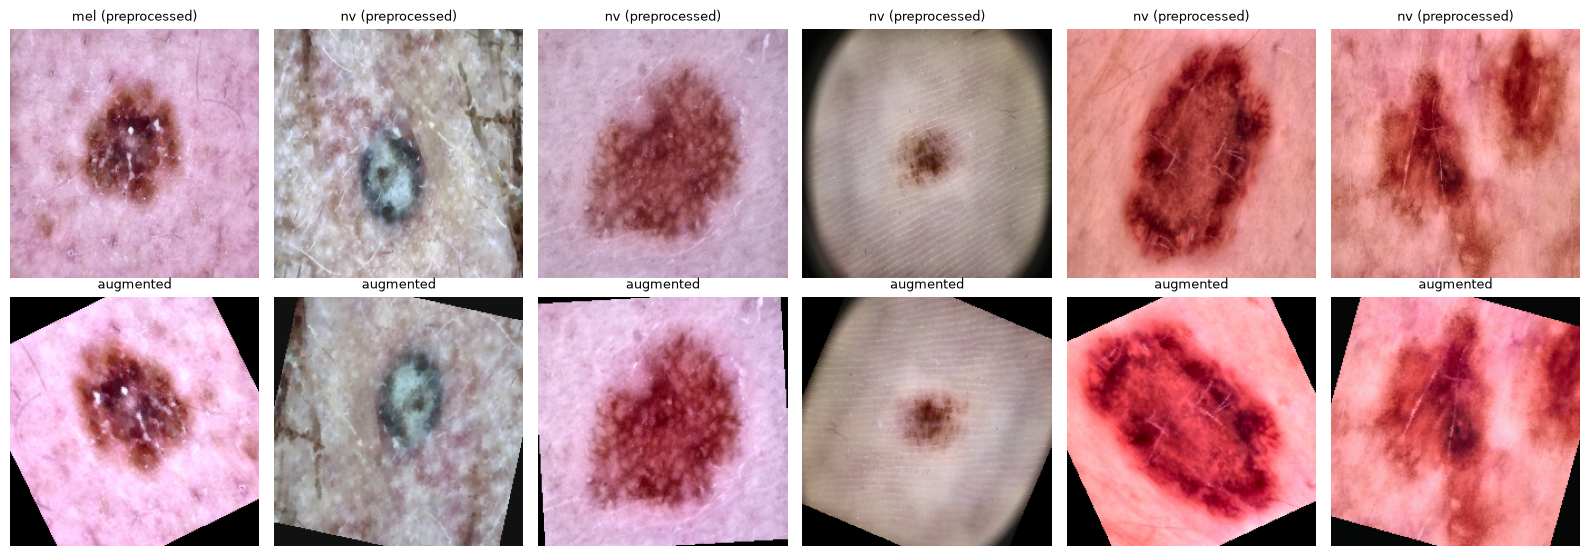

In [6]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

norm_tf = [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
train_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15, hue=0.03),
] + norm_tf)
eval_tf = transforms.Compose([transforms.ToPILImage()] + norm_tf)

class SkinLesionDataset(Dataset):
    def __init__(self, df, transform):
        self.df, self.transform = df.reset_index(drop=True), transform
    def __len__(self):
        return len(self.df)
    def load(self, idx):
        row = self.df.iloc[idx]
        cached = PROCESSED_DIR / f"{row.image_id}.jpg"
        return load_image_rgb(cached) if cached.exists() else preprocess_image(load_image_rgb(row.path))
    def __getitem__(self, idx):
        return self.transform(self.load(idx)), int(self.df.iloc[idx]["label"])

pin = torch.cuda.is_available()
train_loader = DataLoader(SkinLesionDataset(train_df, train_tf), batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin)
val_loader = DataLoader(SkinLesionDataset(val_df, eval_tf), batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=pin)
test_loader = DataLoader(SkinLesionDataset(test_df, eval_tf), batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=pin)

# visualise a few augmented training samples
inv = lambda t: np.clip(t.permute(1, 2, 0).numpy() * IMAGENET_STD + IMAGENET_MEAN, 0, 1)
ds = train_loader.dataset
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for j in range(6):
    idx = int(np.random.randint(len(ds)))
    axes[0, j].imshow(ds.load(idx)); axes[0, j].set_title(f"{ds.df.dx[idx]} (preprocessed)", fontsize=9)
    axes[1, j].imshow(inv(ds[idx][0])); axes[1, j].set_title("augmented", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Handling class imbalance: weighted cross-entropy
With ~67% nevi, an unweighted loss would let the model ignore rare classes. Each class *c* gets the
weight √(N / (K · N_c)) (the square root of scikit-learn's *balanced* weights, normalised to mean 1).
The square root up-weights rare classes without over-correcting, which keeps precision on the large
classes reasonable. A small label smoothing (0.05) further regularises the output probabilities.

In [7]:
from sklearn.utils.class_weight import compute_class_weight
w = compute_class_weight("balanced", classes=np.arange(len(CLASS_NAMES)), y=train_df["label"].to_numpy())
w = np.sqrt(w); w = w / w.mean()
class_weights = torch.tensor(w, dtype=torch.float32, device=DEVICE)
display(pd.DataFrame({"train images": train_df.dx.value_counts().reindex(CLASS_NAMES).values,
                      "loss weight": w.round(3)}, index=CLASS_NAMES))

,train images,loss weight
akiec,222,1.104
bcc,361,0.866
bkl,772,0.592
df,71,1.952
mel,773,0.592
nv,4683,0.240
vasc,99,1.653


## 6. Model: ResNet50 with transfer learning

**ResNet50** (He et al., 2016) introduced **residual (skip) connections**, which let gradients flow through
very deep networks. It stacks 16 *bottleneck* blocks (1×1 → 3×3 → 1×1 convolutions) in four stages.
ResNet50 is one of the most widely used backbones in dermoscopy research (e.g. Brinker et al., 2019,
where it outperformed most dermatologists). It has ~23.5 M parameters.

* ImageNet weights: `ResNet50_Weights.IMAGENET1K_V2`
* New head: `Dropout(0.3) → Linear(2048, 7)`
* Grad-CAM target layer: `layer4[-1]` (last bottleneck block, 2048 × 7 × 7 feature maps)

All layers are fine-tuned (no frozen layers): the low-level filters learned on ImageNet (edges, colours,
textures) are a strong initialisation, and fine-tuning adapts the higher layers to dermoscopic patterns
such as pigment networks, globules, streaks and irregular borders.

In [8]:
import torch.nn as nn
from torchvision import models

def build_model(name, num_classes=len(CLASS_NAMES), pretrained=True):
    if name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier[1].in_features, num_classes))
    elif name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, num_classes))
    elif name == "densenet121":
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier.in_features, num_classes))
    else:
        raise ValueError(name)
    return m

def get_target_layer(model, name):
    return {"efficientnet_b0": lambda: model.features[-1],
            "resnet50": lambda: model.layer4[-1],
            "densenet121": lambda: model.features.denseblock4}[name]()

model = build_model(MODEL_NAME).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME}: {n_params / 1e6:.2f} M parameters (all trainable) on {DEVICE}")

resnet50: 23.52 M parameters (all trainable) on mps


## 7. Training
* **Optimiser:** AdamW (Adam with decoupled weight decay), learning rate 0.0003, weight decay 1e-4
* **LR scheduler:** `ReduceLROnPlateau`: the learning rate is multiplied by 0.3 when the validation macro-F1
  has not improved for 2 epochs
* **Model selection / early stopping:** the checkpoint with the best **validation macro-F1** is kept
  (macro-F1 treats all classes equally, unlike accuracy which is dominated by `nv`). Training stops when
  macro-F1 has not improved for 4 epochs (only after at least 10 epochs), or after 15 epochs.

In [9]:
from sklearn.metrics import f1_score

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.3, patience=2)
CKPT_PATH = MODELS_DIR / f"{MODEL_NAME}.pth"

def run_epoch(loader, train):
    model.train(train)
    total, preds, targets = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
            total += loss.item() * x.size(0)
            preds.append(logits.argmax(1).cpu()); targets.append(y.cpu())
    p, t = torch.cat(preds).numpy(), torch.cat(targets).numpy()
    return total / len(loader.dataset), float((p == t).mean()), float(f1_score(t, p, average="macro"))

set_seed()
history, best_f1, bad, t_start = [], -1.0, 0, time.time()
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc, tr_f1 = run_epoch(train_loader, True)
    va_loss, va_acc, va_f1 = run_epoch(val_loader, False)
    scheduler.step(va_f1)
    lr = optimizer.param_groups[0]["lr"]
    history.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc, train_f1=tr_f1,
                        val_loss=va_loss, val_acc=va_acc, val_f1=va_f1, lr=lr, seconds=time.time() - t0))
    msg = (f"Epoch {epoch:2d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
           f"val loss {va_loss:.4f} acc {va_acc:.4f} macro-F1 {va_f1:.4f} | lr {lr:.1e} | {time.time() - t0:.0f}s")
    if va_f1 > best_f1:
        best_f1, bad = va_f1, 0
        torch.save({"model_name": MODEL_NAME, "state_dict": model.state_dict(), "class_names": CLASS_NAMES,
                    "img_size": IMG_SIZE, "epoch": epoch, "val_f1": va_f1, "val_acc": va_acc, "quick": False},
                   CKPT_PATH)
        msg += "  <- best, saved"
    else:
        bad += 1
    print(msg, flush=True)
    if bad >= PATIENCE and epoch >= MIN_EPOCHS:
        print(f"Early stopping: no improvement for {PATIENCE} epochs.")
        break

train_minutes = (time.time() - t_start) / 60
hist = pd.DataFrame(history)
hist.to_csv(OUT_DIR / "training_history.csv", index=False)
best_epoch = int(hist.loc[hist.val_f1.idxmax(), "epoch"])
print(f"\nTraining time {train_minutes:.1f} min | best epoch {best_epoch} | best val macro-F1 {best_f1:.4f}")
print(f"Model saved to {CKPT_PATH}")

Epoch  1/15 | train loss 1.4552 acc 0.7175 | val loss 1.3684 acc 0.7167 macro-F1 0.5229 | lr 3.0e-04 | 133s  <- best, saved


Epoch  2/15 | train loss 1.2272 acc 0.7665 | val loss 1.2038 acc 0.7866 macro-F1 0.6215 | lr 3.0e-04 | 127s  <- best, saved


Epoch  3/15 | train loss 1.1454 acc 0.7860 | val loss 1.2624 acc 0.7644 macro-F1 0.5483 | lr 3.0e-04 | 132s


Epoch  4/15 | train loss 1.0893 acc 0.8070 | val loss 1.2235 acc 0.7631 macro-F1 0.6093 | lr 3.0e-04 | 136s


Epoch  5/15 | train loss 1.0430 acc 0.8189 | val loss 1.1923 acc 0.7872 macro-F1 0.5940 | lr 9.0e-05 | 147s


Epoch  6/15 | train loss 0.9122 acc 0.8681 | val loss 1.0840 acc 0.8349 macro-F1 0.6919 | lr 9.0e-05 | 143s  <- best, saved


... (5 outputs left out)

Epoch 12/15 | train loss 0.7527 acc 0.9224 | val loss 1.1708 acc 0.8107 macro-F1 0.6676 | lr 9.0e-05 | 153s


Epoch 13/15 | train loss 0.7293 acc 0.9281 | val loss 1.2357 acc 0.8068 macro-F1 0.6712 | lr 2.7e-05 | 126s


Epoch 14/15 | train loss 0.6943 acc 0.9461 | val loss 1.1791 acc 0.8238 macro-F1 0.7038 | lr 2.7e-05 | 126s


Early stopping: no improvement for 4 epochs.

Training time 31.5 min | best epoch 10 | best val macro-F1 0.7196
Model saved to /Users/udaymallikarjun/Documents/sanya/skincancer/skin-cancer-detection/models/resnet50.pth


## 8. Training and validation curves

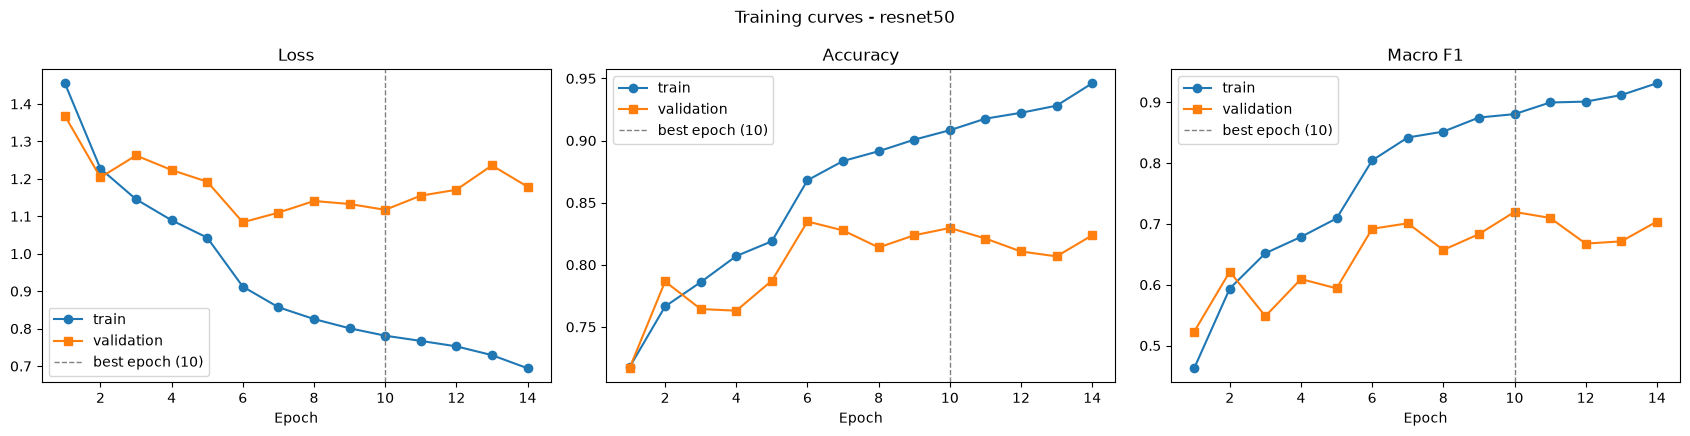

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, key, label in zip(axes, ["loss", "acc", "f1"], ["Loss", "Accuracy", "Macro F1"]):
    ax.plot(hist.epoch, hist[f"train_{key}"], "o-", label="train")
    ax.plot(hist.epoch, hist[f"val_{key}"], "s-", label="validation")
    ax.axvline(best_epoch, color="grey", ls="--", lw=1, label=f"best epoch ({best_epoch})")
    ax.set_xlabel("Epoch"); ax.set_title(label); ax.legend()
plt.suptitle(f"Training curves - {MODEL_NAME}")
plt.tight_layout(); plt.savefig(OUT_DIR / "training_curves.png", dpi=150); plt.show()

## 9. Evaluation on the held-out test set
The best checkpoint is reloaded and evaluated **once** on the test set, which contains only lesions the
model has never seen. Metrics (per class, one-vs-rest):

* **Precision**: of the images predicted as class *c*, the fraction that truly are *c*
* **Recall / sensitivity**: of the images of class *c*, the fraction detected
* **Specificity**: of the images *not* of class *c*, the fraction correctly not assigned to *c*
* **F1**: harmonic mean of precision and recall
* **ROC-AUC**: threshold-independent ranking quality of the class probability

In [11]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_recall_fscore_support, roc_auc_score, roc_curve, auc)
from sklearn.preprocessing import label_binarize

ckpt = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)
model.load_state_dict(ckpt["state_dict"]); model.eval()

probs, labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        probs.append(torch.softmax(model(x.to(DEVICE)), 1).cpu()); labels.append(y)
probs, labels = torch.cat(probs).numpy(), torch.cat(labels).numpy()
preds = probs.argmax(1)
K = len(CLASS_NAMES)

cm = confusion_matrix(labels, preds, labels=range(K))
prec, rec, f1, support = precision_recall_fscore_support(labels, preds, labels=range(K), zero_division=0)
tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; tn = cm.sum() - tp - fp - fn
spec = tn / (tn + fp)
y_bin = label_binarize(labels, classes=range(K))
aucs = np.array([roc_auc_score(y_bin[:, i], probs[:, i]) for i in range(K)])

per_class = pd.DataFrame({"class": CLASS_NAMES, "type": [BINARY_MAP[c] for c in CLASS_NAMES],
                          "precision": prec, "recall_sensitivity": rec, "specificity": spec,
                          "f1": f1, "roc_auc": aucs, "support": support})
overall = {"accuracy": float(accuracy_score(labels, preds)), "balanced_accuracy": float(rec.mean()),
           "macro_precision": float(prec.mean()), "macro_recall_sensitivity": float(rec.mean()),
           "macro_specificity": float(spec.mean()), "macro_f1": float(f1.mean()),
           "weighted_f1": float(f1_score(labels, preds, average="weighted")),
           "macro_roc_auc": float(aucs.mean()), "n_test": int(len(labels))}

report = classification_report(labels, preds, target_names=CLASS_NAMES, digits=4, zero_division=0)
(OUT_DIR / "classification_report.txt").write_text(report)
per_class.to_csv(OUT_DIR / "per_class_metrics.csv", index=False)
print("Classification report (test set)\n")
print(report)
display(pd.Series(overall, name=MODEL_NAME).to_frame().round(4))
display(per_class.set_index("class").round(4))

Classification report (test set)

              precision    recall  f1-score   support

       akiec     0.7500    0.5192    0.6136        52
         bcc     0.7467    0.7887    0.7671        71
         bkl     0.5750    0.6886    0.6267       167
          df     0.5556    0.5000    0.5263        20
         mel     0.4783    0.5928    0.5294       167
          nv     0.9293    0.8765    0.9021      1004
        vasc     0.8947    0.8095    0.8500        21

    accuracy                         0.8016      1502
   macro avg     0.7042    0.6822    0.6879      1502
weighted avg     0.8194    0.8016    0.8079      1502



,resnet50
accuracy,0.8016
balanced_accuracy,0.6822
macro_precision,0.7042
macro_recall_sensitivity,0.6822
macro_specificity,0.9564
macro_f1,0.6879
weighted_f1,0.8079
macro_roc_auc,0.9447
n_test,1502.0000


,type,precision,recall_sensitivity,specificity,f1,roc_auc,support
class,,,,,,,
akiec,Malignant,0.7500,0.5192,0.9938,0.6136,0.9741,52
bcc,Malignant,0.7467,0.7887,0.9867,0.7671,0.9660,71
bkl,Benign,0.5750,0.6886,0.9363,0.6267,0.9227,167
df,Benign,0.5556,0.5000,0.9946,0.5263,0.9419,20
mel,Malignant,0.4783,0.5928,0.9191,0.5294,0.8871,167
nv,Benign,0.9293,0.8765,0.8655,0.9021,0.9431,1004
vasc,Benign,0.8947,0.8095,0.9986,0.8500,0.9777,21


### 9.1 Confusion matrix
Rows are the true classes, columns the predictions; colours show row-normalised rates (= per-class recall on the diagonal).

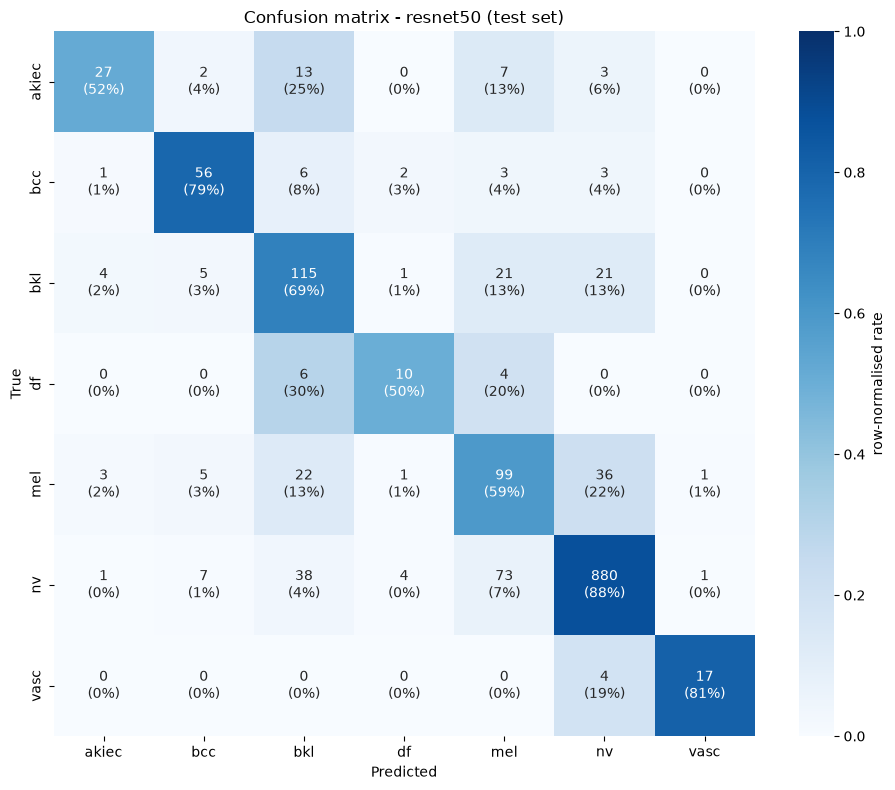

In [12]:
def plot_cm(cm, names, title, path, size):
    rate = cm / cm.sum(1, keepdims=True)
    annot = np.array([[f"{cm[i, j]}\n({rate[i, j]:.0%})" for j in range(len(names))] for i in range(len(names))])
    plt.figure(figsize=size)
    sns.heatmap(rate, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, xticklabels=names, yticklabels=names,
                cbar_kws={"label": "row-normalised rate"})
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(title)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

plot_cm(cm, CLASS_NAMES, f"Confusion matrix - {MODEL_NAME} (test set)", OUT_DIR / "confusion_matrix.png", (9.5, 8))

### 9.2 ROC curves
One-vs-rest ROC curve for each class, and the benign-vs-malignant ROC curve using the summed probability of the three malignant classes as the score.

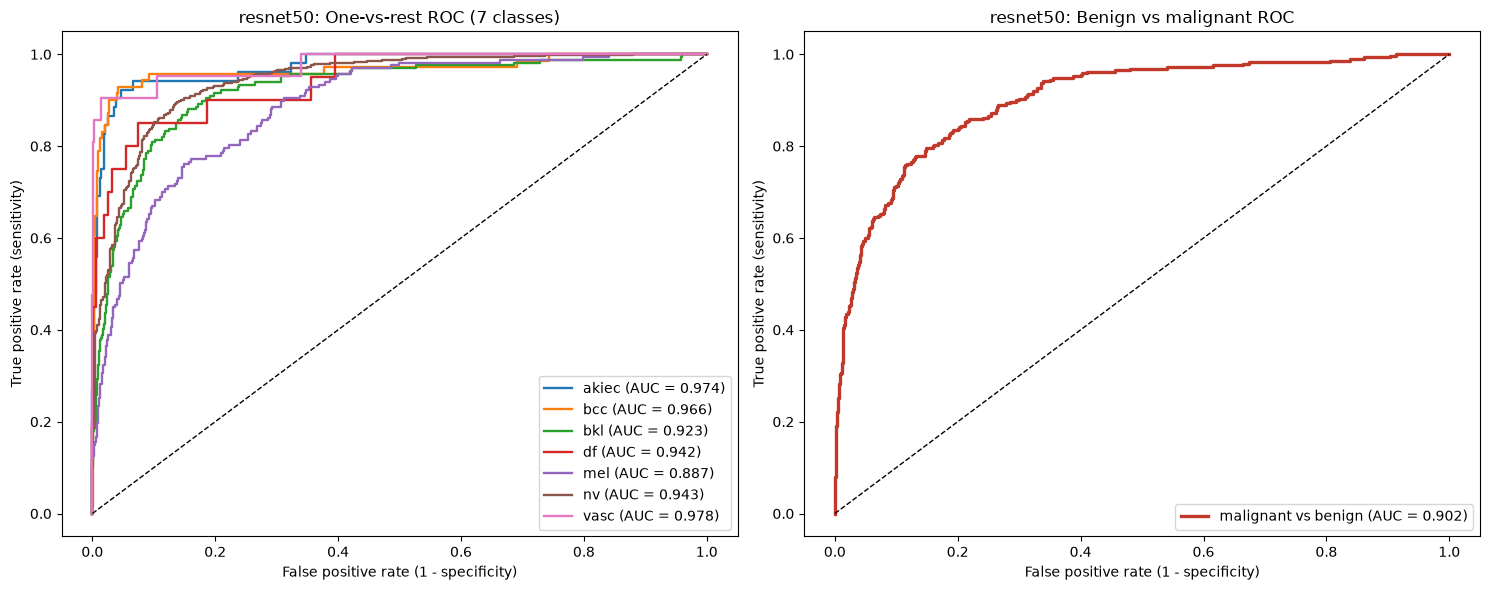

In [13]:
true_m = np.isin(labels, MALIGNANT_IDX).astype(int)
score_m = probs[:, MALIGNANT_IDX].sum(1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for i, c in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
    axes[0].plot(fpr, tpr, lw=1.7, label=f"{c} (AUC = {aucs[i]:.3f})")
fpr, tpr, _ = roc_curve(true_m, score_m)
axes[1].plot(fpr, tpr, lw=2.4, color="#c0392b", label=f"malignant vs benign (AUC = {auc(fpr, tpr):.3f})")
for ax, t in zip(axes, ["One-vs-rest ROC (7 classes)", "Benign vs malignant ROC"]):
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title(f"{MODEL_NAME}: {t}")
    ax.set_xlabel("False positive rate (1 - specificity)"); ax.set_ylabel("True positive rate (sensitivity)")
    ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(OUT_DIR / "roc_curves.png", dpi=150); plt.show()

### 9.3 Benign vs malignant
The predicted class is mapped to its group (mel, bcc, akiec → **Malignant**; nv, bkl, df, vasc → **Benign**).
For screening, **sensitivity** (missed cancers are costly) is the most important number.

,benign vs malignant
accuracy,0.8655
precision,0.6384
sensitivity,0.7000
specificity,0.9051
f1,0.6678
roc_auc,0.9020


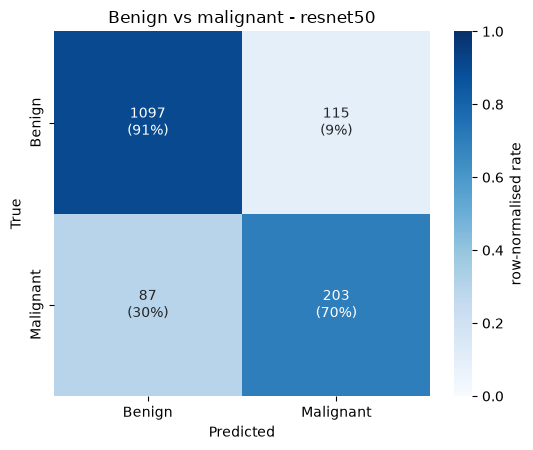

In [14]:
pred_m = np.isin(preds, MALIGNANT_IDX).astype(int)
bcm = confusion_matrix(true_m, pred_m, labels=[0, 1])
btn, bfp, bfn, btp = bcm.ravel()
binary = {"accuracy": float((btp + btn) / bcm.sum()), "precision": float(btp / (btp + bfp)),
          "sensitivity": float(btp / (btp + bfn)), "specificity": float(btn / (btn + bfp)),
          "f1": float(f1_score(true_m, pred_m)), "roc_auc": float(roc_auc_score(true_m, score_m)),
          "confusion_matrix": bcm.tolist()}
display(pd.Series({k: v for k, v in binary.items() if k != "confusion_matrix"}, name="benign vs malignant").round(4).to_frame())
plot_cm(bcm, ["Benign", "Malignant"], f"Benign vs malignant - {MODEL_NAME}", OUT_DIR / "confusion_matrix_binary.png", (5.5, 4.6))

## 10. Explainable AI: Grad-CAM
**Grad-CAM** (Selvaraju et al., 2017) is implemented from scratch with PyTorch hooks:

1. a *forward hook* on the last convolutional block stores its activation maps **A** (K × 7 × 7) and
   registers a *tensor hook* that receives the gradient ∂y_c/∂A during back-propagation,
2. each channel weight is the spatial mean of its gradient: α_k = mean_ij(∂y_c / ∂A_k,ij),
3. the class activation map is ReLU(Σ_k α_k · A_k), up-sampled to 224 × 224 and normalised to [0, 1].

Red / yellow regions are the parts of the image that increased the score of the predicted class.
We visualise 6 test images, one per class (mel, bcc, akiec, nv, bkl, vasc), chosen at random rather
than by prediction quality.

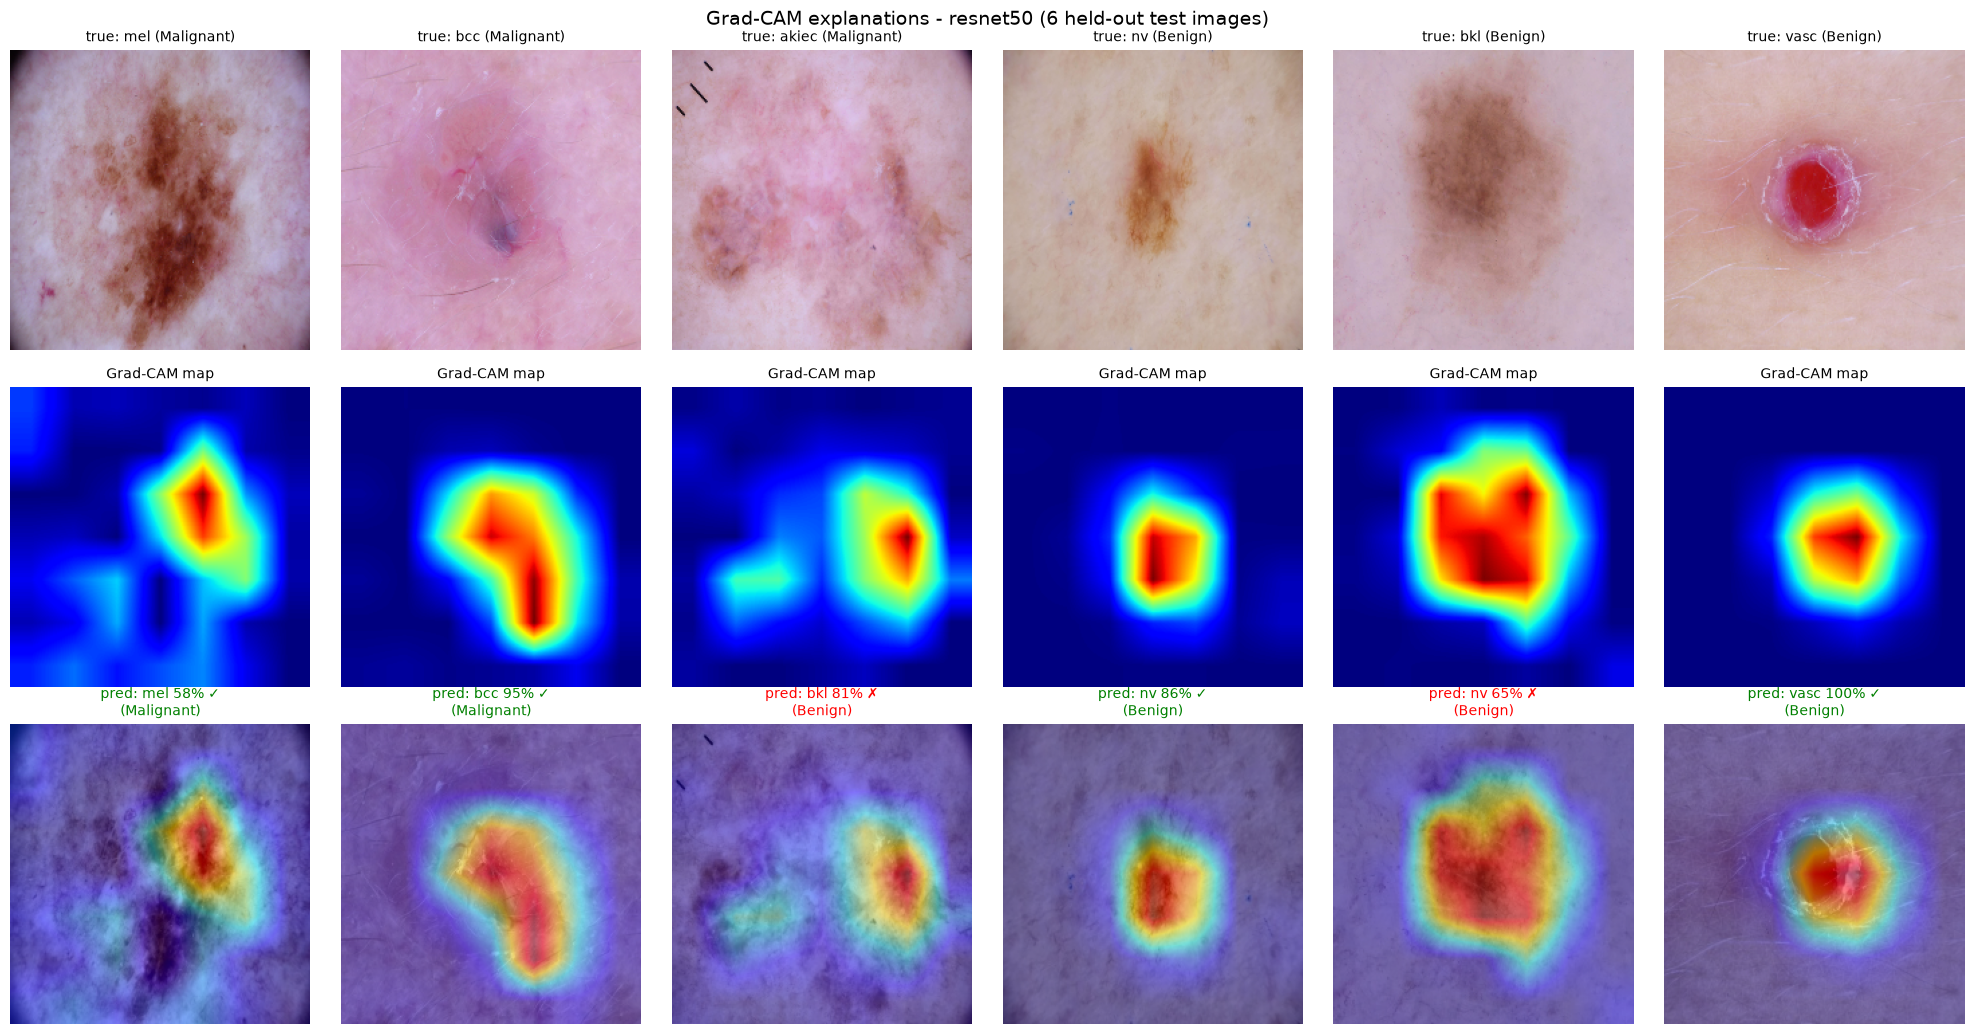

In [15]:
import torch.nn.functional as F

class GradCAM:
    def __init__(self, model, target_layer):
        self.model, self.activations, self.gradients = model, None, None
        self.handle = target_layer.register_forward_hook(self._hook)
    def _hook(self, module, inp, out):
        self.activations = out.detach()
        out.register_hook(lambda g: setattr(self, "gradients", g.detach()))
    def __call__(self, x, class_idx=None):
        self.model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = self.model(x)
            if class_idx is None:
                class_idx = int(logits.argmax(1))
            logits[0, class_idx].backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx, torch.softmax(logits, 1)[0].detach().cpu().numpy()

def overlay(img, cam, alpha=0.45):
    heat = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return np.uint8(np.clip((1 - alpha) * img + alpha * heat, 0, 255))

gradcam = GradCAM(model, get_target_layer(model, MODEL_NAME))
demo = pd.concat([test_df[test_df.dx == c].sample(1, random_state=SEED) for c in ["mel", "bcc", "akiec", "nv", "bkl", "vasc"]])
fig, axes = plt.subplots(3, 6, figsize=(20, 10.5))
for j, row in enumerate(demo.itertuples()):
    pre = load_image_rgb(PROCESSED_DIR / f"{row.image_id}.jpg")
    x = torch.from_numpy(normalize(pre).transpose(2, 0, 1)).unsqueeze(0).to(DEVICE)
    cam, idx, p = gradcam(x)
    pc = CLASS_NAMES[idx]
    ok = "✓" if pc == row.dx else "✗"
    axes[0, j].imshow(cv2.resize(load_image_rgb(row.path), (IMG_SIZE, IMG_SIZE)))
    axes[0, j].set_title(f"true: {row.dx} ({BINARY_MAP[row.dx]})", fontsize=10)
    axes[1, j].imshow(cam, cmap="jet"); axes[1, j].set_title("Grad-CAM map", fontsize=10)
    axes[2, j].imshow(overlay(pre, cam))
    axes[2, j].set_title(f"pred: {pc} {p[idx]:.0%} {ok}\n({BINARY_MAP[pc]})", fontsize=10,
                         color="green" if pc == row.dx else "red")
for ax in axes.ravel(): ax.axis("off")
plt.suptitle(f"Grad-CAM explanations - {MODEL_NAME} (6 held-out test images)", fontsize=14)
plt.tight_layout(); plt.savefig(OUT_DIR / "gradcam_test_images.png", dpi=120); plt.show()
gradcam.handle.remove()

## 11. Save metrics and predictions

In [16]:
pred_df = test_df[["image_id", "lesion_id", "dx"]].reset_index(drop=True)
pred_df["pred"] = [CLASS_NAMES[i] for i in preds]
pred_df["confidence"] = probs.max(1)
for i, c in enumerate(CLASS_NAMES):
    pred_df[f"p_{c}"] = probs[:, i]
pred_df.to_csv(OUT_DIR / "test_predictions.csv", index=False)

metrics = {"model": MODEL_NAME, "checkpoint": CKPT_PATH.name, "best_epoch": best_epoch,
           "epochs_run": int(len(hist)), "train_minutes": round(train_minutes, 2), "device": str(DEVICE),
           "params_millions": round(n_params / 1e6, 2), "img_size": IMG_SIZE, "batch_size": BATCH_SIZE,
           "best_val_f1": best_f1, "overall": overall, "binary": binary,
           "per_class": per_class.to_dict(orient="records")}
for path in (RESULTS_DIR / f"{MODEL_NAME}_metrics.json", OUT_DIR / "metrics.json"):
    path.write_text(json.dumps(metrics, indent=2))
(OUT_DIR / "training_summary.json").write_text(json.dumps(
    {"model": MODEL_NAME, "epochs_run": int(len(hist)), "best_val_f1": best_f1, "train_minutes": train_minutes,
     "device": str(DEVICE), "train_size": len(train_df), "quick": False}, indent=2))
print("Saved:", RESULTS_DIR / f"{MODEL_NAME}_metrics.json")
print(f"\n{MODEL_NAME} test results: accuracy {overall['accuracy']:.4f} | balanced acc {overall['balanced_accuracy']:.4f} | "
      f"macro-F1 {overall['macro_f1']:.4f} | macro AUC {overall['macro_roc_auc']:.4f}")
print(f"Benign vs malignant: sensitivity {binary['sensitivity']:.4f} | specificity {binary['specificity']:.4f} | "
      f"AUC {binary['roc_auc']:.4f}")

Saved: /Users/udaymallikarjun/Documents/sanya/skincancer/skin-cancer-detection/results/resnet50_metrics.json

resnet50 test results: accuracy 0.8016 | balanced acc 0.6822 | macro-F1 0.6879 | macro AUC 0.9447
Benign vs malignant: sensitivity 0.7000 | specificity 0.9051 | AUC 0.9020


## Summary
* ResNet50 was fine-tuned from ImageNet weights with augmentation, a class-weighted loss, AdamW,
  `ReduceLROnPlateau` and early stopping on validation macro-F1.
* Test metrics (accuracy, precision, sensitivity, specificity, F1, ROC-AUC, per class and benign vs
  malignant) are printed above and saved to `results/resnet50_metrics.json`.
* The trained weights are in `models/resnet50.pth`; they can be loaded by `src/predict.py` and the
  Streamlit app (`streamlit run app.py`).
* Continue with **05_model_comparison.ipynb** after all three model notebooks have run.